# MODELO PARA LA CLASIFICACIÓN DE MICROESTRUCTURAS BAINITÍCAS

## EfficientNetB0 - Pipeline propuesto

In [1]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

## Extración y organización de datos

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


i                            316
ii                           310
iii                          306
Tamaño de la imagen: (768, 768), modo: P


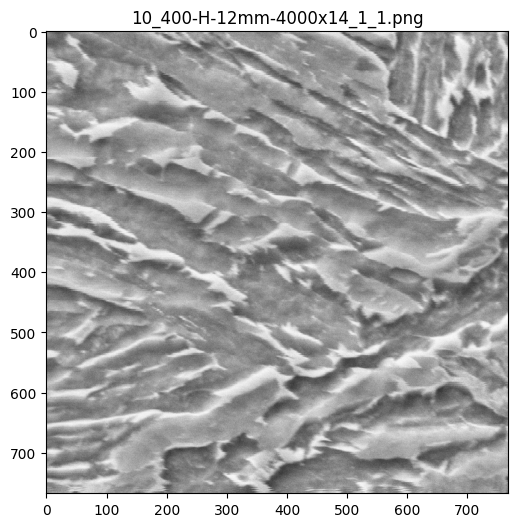

In [5]:
import os
from PIL import Image

ruta = '/content/drive/MyDrive/Proyecto IA2/Bainitic Microstructures/im_train'

# 1 Cuántas imágenes hay por clase
for clase in sorted(os.listdir(ruta)):
  carpeta = os.path.join(ruta, clase)
  if os.path.isdir(carpeta) and not clase.startswith("."):
    print(f"{clase:28s} {len(os.listdir(carpeta))}")

# Tamaño y modo de una de las imagenes del dataset original
ejemplo_clase = "i"
ejemplo = os.listdir(os.path.join(ruta, ejemplo_clase))[0]
img = Image.open(os.path.join(ruta, ejemplo_clase, ejemplo))
print(f"Tamaño de la imagen: {img.size}, modo: {img.mode}")

# Grafias imagen original sin redimensión
plt.figure(figsize=(8, 6))
plt.imshow(img, cmap="gray")
plt.title(ejemplo)
plt.show()

In [6]:
ruta = '/content/drive/MyDrive/Proyecto IA2/Bainitic Microstructures/im_train'
CLASES_EXCLUIDAS = [""]
# 1) Recorrer las carpetas y anotar (ruta, clase) de cada imagen
filas = []
for clase in sorted(os.listdir(ruta)):
    carpeta = os.path.join(ruta, clase)
    if not os.path.isdir(carpeta) or clase.startswith("."):
        continue                                  # ignora .ipynb_checkpoints
    if clase in CLASES_EXCLUIDAS:
        continue                                  # aquí se excluye la clase
    for archivo in os.listdir(carpeta):
        if archivo.lower().endswith(".png"):
            filas.append({"ruta": os.path.join(carpeta, archivo), "clase": clase})

df = pd.DataFrame(filas)

# 2) Pasar cada clase a un número (0, 1, 2, ...)
clases = sorted(df["clase"].unique())
clase_a_id = {c: i for i, c in enumerate(clases)}
df["label"] = df["clase"].map(clase_a_id)

print("Clases:", clases)
print("Total imágenes:", len(df))
print(df["clase"].value_counts())
df

Clases: ['i', 'ii', 'iii']
Total imágenes: 932
clase
i      316
ii     310
iii    306
Name: count, dtype: int64


,ruta,clase,label
0,/content/drive/MyDrive/Proyecto IA2/Bainitic M...,i,0
1,/content/drive/MyDrive/Proyecto IA2/Bainitic M...,i,0
2,/content/drive/MyDrive/Proyecto IA2/Bainitic M...,i,0
3,/content/drive/MyDrive/Proyecto IA2/Bainitic M...,i,0
4,/content/drive/MyDrive/Proyecto IA2/Bainitic M...,i,0
...,...,...,...
927,/content/drive/MyDrive/Proyecto IA2/Bainitic M...,iii,2
928,/content/drive/MyDrive/Proyecto IA2/Bainitic M...,iii,2
929,/content/drive/MyDrive/Proyecto IA2/Bainitic M...,iii,2
930,/content/drive/MyDrive/Proyecto IA2/Bainitic M...,iii,2


In [7]:
from sklearn.model_selection import train_test_split

# Primero: 70% train, 30% "resto"
train_df, val_df = train_test_split(
    df, test_size=0.30, stratify=df["label"], random_state=42
)

# Verificar que cada conjunto tenga todas las clases
resumen = pd.concat({
    "train": train_df["clase"].value_counts(),
    "val":   val_df["clase"].value_counts(),
}, axis=1)
print(resumen)
print("\nTotales:", len(train_df), len(val_df))

       train  val
clase            
i        221   95
ii       217   93
iii      214   92

Totales: 652 280


(32, 224, 224, 1) (32,)


ValueError: num must be an integer with 1 <= num <= 8, not 9

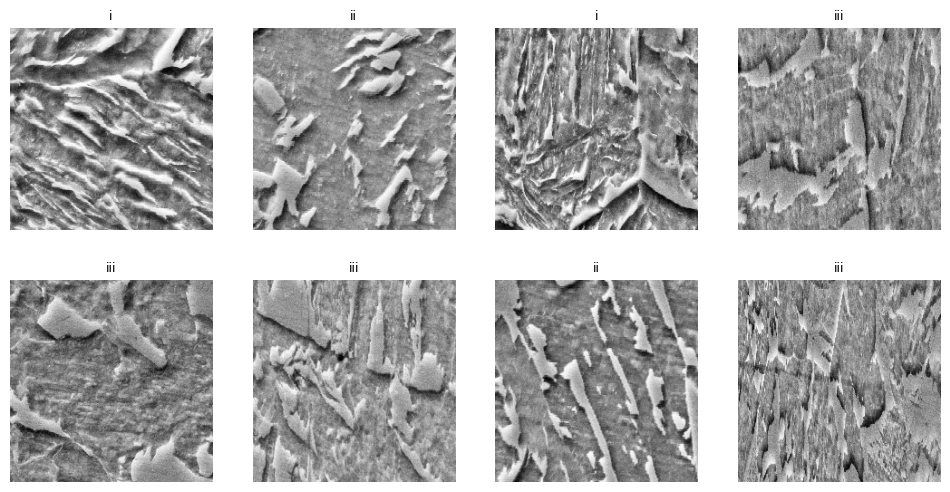

In [8]:
IMG_SIZE = 224
FILAS_UTILES = 481
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE

def cargar_imagen(ruta,label):
  img = tf.io.read_file(ruta)
  img = tf.image.decode_png(img, channels=1)  # convierte el modo "P" a gris
  img = img[:FILAS_UTILES, :, :]              # recorte de la franja inferior
  img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
  return img, label

def crear_dataset(tabla, entrenamiento=False):
  ds = tf.data.Dataset.from_tensor_slices((tabla["ruta"].values, tabla["label"].values))
  ds = ds.map(cargar_imagen, num_parallel_calls=AUTOTUNE)
  ds = ds.cache()                        # guarde en memoeria tras la 1° época
  if entrenamiento:
    ds = ds.shuffle(len(tabla), seed=42) # solo se baraja train
  return ds.batch(BATCH).prefetch(AUTOTUNE)

train_ds = crear_dataset(train_df, entrenamiento=True)
val_ds = crear_dataset(val_df)

# Comprobación rápida
imgs, labs = next(iter(train_ds))
print(imgs.shape, labs.shape)
plt.figure(figsize=(12, 6))
for i in range(9):
  plt.subplot(2, 4, i + 1)
  plt.imshow(imgs[i].numpy().squeeze(), cmap="gray")
  plt.title(clases[labs[i]], fontsize=9)
  plt.axis("off")
plt.tight_layout()
plt.show()

## **AUMENTO DE DATOS**

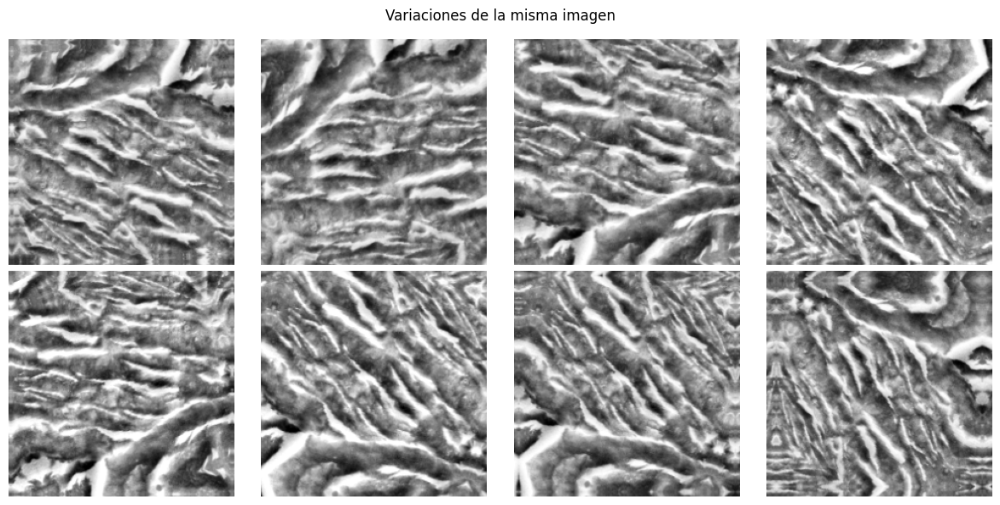

In [9]:
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1, fill_mode="reflect"),
    layers.RandomZoom(0.1, fill_mode="reflect"),
    layers.RandomContrast(0.2),
], name="augmentation")

# Ver cómo transforma UNA imagen
img = imgs[0:1]
plt.figure(figsize=(12, 6))
for k in range(8):
    aumentada = data_augmentation(img, training=True)
    plt.subplot(2, 4, k + 1)
    plt.imshow(aumentada[0].numpy().squeeze(), cmap="gray")
    plt.axis("off")
plt.suptitle("Variaciones de la misma imagen")
plt.tight_layout(); plt.show()

In [10]:
from sklearn.utils.class_weight import compute_class_weight

pesos = compute_class_weight("balanced",
                             classes=np.unique(train_df["label"]),
                             y=train_df["label"])
class_weight = dict(enumerate(pesos))
for c, w in zip(clases, pesos):
    print(f"{c:28s} peso = {w:.2f}")

i                            peso = 0.98
ii                           peso = 1.00
iii                          peso = 1.02


## **PIPELINE PROPUESTO**

In [13]:
def crear_cnn_base(n_clases):
    entradas = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1))
    x = data_augmentation(entradas)
    x = layers.Rescaling(1/255)(x)

    for filtros in [64, 128, 256, 512]:
        x = layers.Conv2D(filtros, 3, padding="same", activation="relu")(x)
        x = layers.BatchNormalization(momentum=0.9)(x)
        x = layers.MaxPooling2D()(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(1024, activation="relu")(x)
    x = layers.Dense(512, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    salidas = layers.Dense(n_clases, activation="softmax")(x)
    return tf.keras.Model(entradas, salidas, name="cnn_base")

modelo = crear_cnn_base(len(clases))
modelo.compile(optimizer=tf.keras.optimizers.Adam(0.001),
               loss="sparse_categorical_crossentropy",
               metrics=["accuracy"])
modelo.summary()

Model: "cnn_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 224, 224, 64)   │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 224, 224, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 112, 112, 128)  │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 56, 56, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 28, 28, 512)    │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1024)           │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 3)              │         1,539 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,605,315 (9.94 MB)

 Trainable params: 2,603,395 (9.93 MB)

 Non-trainable params: 1,920 (7.50 KB)

In [14]:
callbacks = [
    #tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=10,
                                     #restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                         patience=4, verbose=1),
]

historia = modelo.fit(train_ds, validation_data=val_ds, epochs=50,
                      class_weight=class_weight, callbacks=callbacks)

Epoch 1/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 10s 295ms/step - accuracy: 0.5276 - loss: 1.1809 - val_accuracy: 0.3286 - val_loss: 8.8331 - learning_rate: 0.0010
Epoch 2/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 6s 284ms/step - accuracy: 0.6779 - loss: 0.7287 - val_accuracy: 0.3321 - val_loss: 13.7053 - learning_rate: 0.0010
Epoch 3/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 6s 289ms/step - accuracy: 0.7393 - loss: 0.6577 - val_accuracy: 0.3286 - val_loss: 5.7211 - learning_rate: 0.0010
Epoch 4/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 6s 301ms/step - accuracy: 0.8021 - loss: 0.5030 - val_accuracy: 0.5964 - val_loss: 0.8013 - learning_rate: 0.0010
Epoch 5/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 6s 302ms/step - accuracy: 0.7929 - loss: 0.4654 - val_accuracy: 0.5643 - val_loss: 2.5872 - learning_rate: 0.0010
Epoch 6/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 6s 303ms/step - accuracy: 0.8451 - loss: 0.4295 - val_accuracy: 0.6179 - val_loss: 0.9711 - learning_rate: 0.0010
Epoch 7/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 6s 289ms/step - accuracy: 0.8512 - loss: 0.3774 

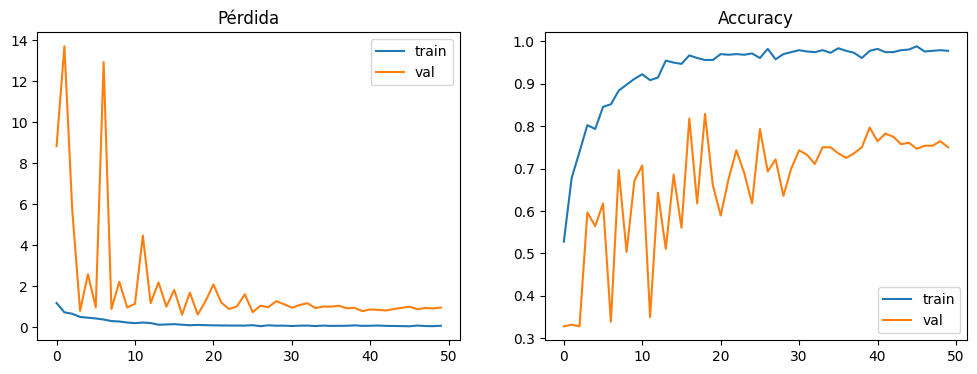

In [15]:
h = historia.history
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="val")
ax[0].set_title("Pérdida"); ax[0].legend()
ax[1].plot(h["accuracy"], label="train"); ax[1].plot(h["val_accuracy"], label="val")
ax[1].set_title("Accuracy"); ax[1].legend()
plt.show()

## **Features y Filtros del pipeline propuesto**

(3, 3, 128, 256)


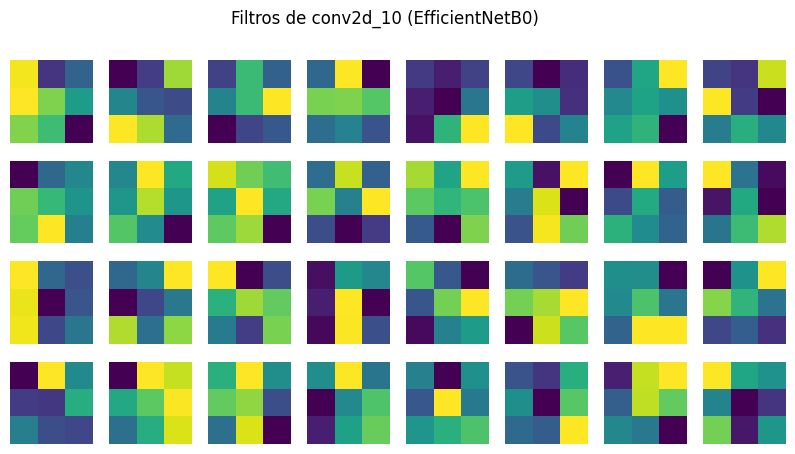

In [30]:
import matplotlib.pyplot as plt

capa = "conv2d_10"

layer = modelo.get_layer(capa)   # primera conv: (3, 3, 3, 32)
w = layer.get_weights()[0]
print(w.shape)

n = min(w.shape[-1], 32)
plt.figure(figsize=(10, 5))
for i in range(n):
    f = w[:, :, :, i]
    f = (f - f.min()) / (f.max() - f.min() + 1e-8)   # normalizar cada filtro por separado
    plt.subplot(4, 8, i + 1)
    if f.shape[-1] == 3:
        plt.imshow(f)                          # RGB
    else:
        plt.imshow(f.mean(axis=-1), cmap="viridis")   # capas profundas: promedio de canales
    plt.axis("off")
plt.suptitle(f"Filtros de {capa} (EfficientNetB0)")
plt.show()

### **Visualizar Activaciones Intermedias del Pipeline Propuesto (CNN Base)**

A continuación, adaptamos el código de visualización de mapas de características para el modelo personalizado `modelo`. Buscaremos dinámicamente las capas de tipo `Conv2D` para extraer y visualizar qué está aprendiendo la CNN base.

Capas convolucionales detectadas en el modelo base: ['conv2d_8', 'conv2d_9', 'conv2d_10', 'conv2d_11']

Generando mapas de características para una imagen de ejemplo:


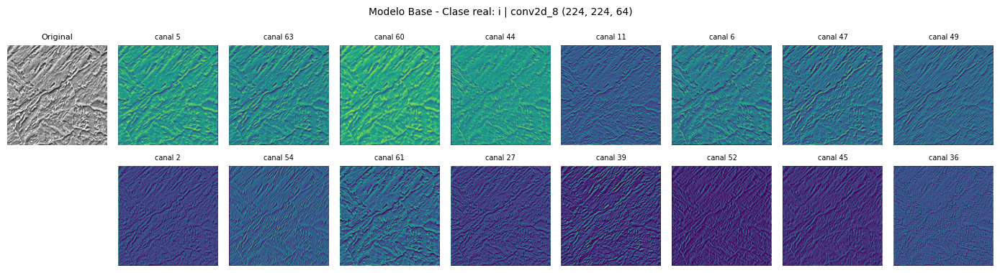

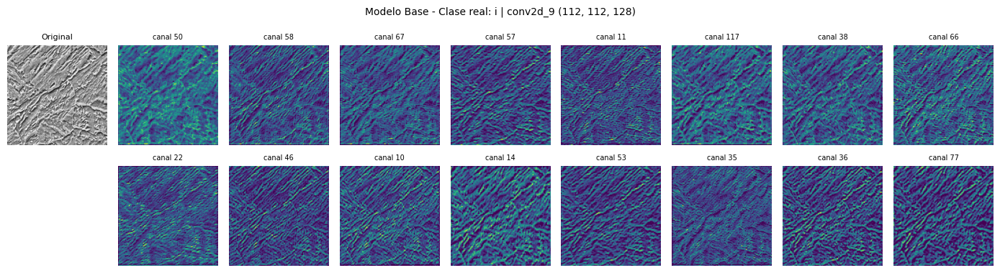

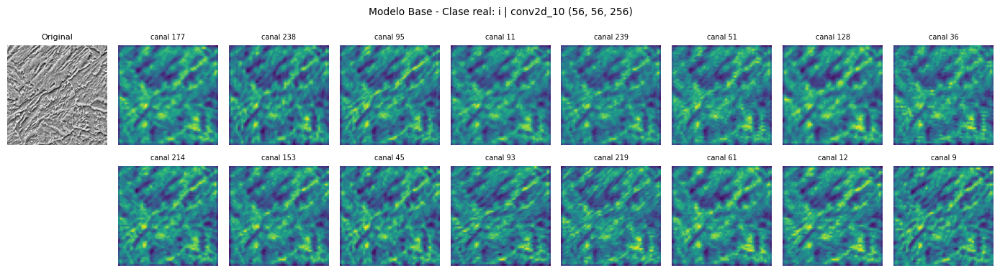

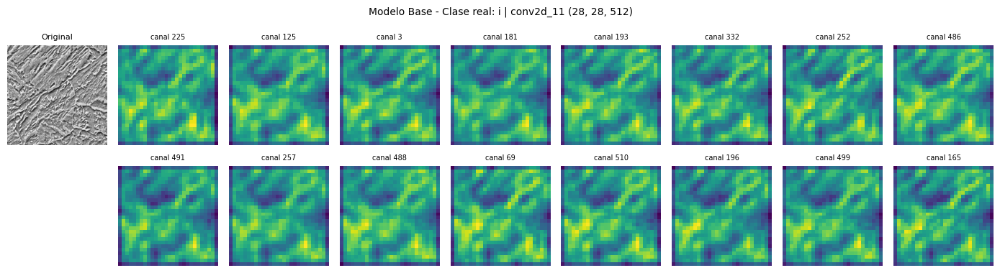

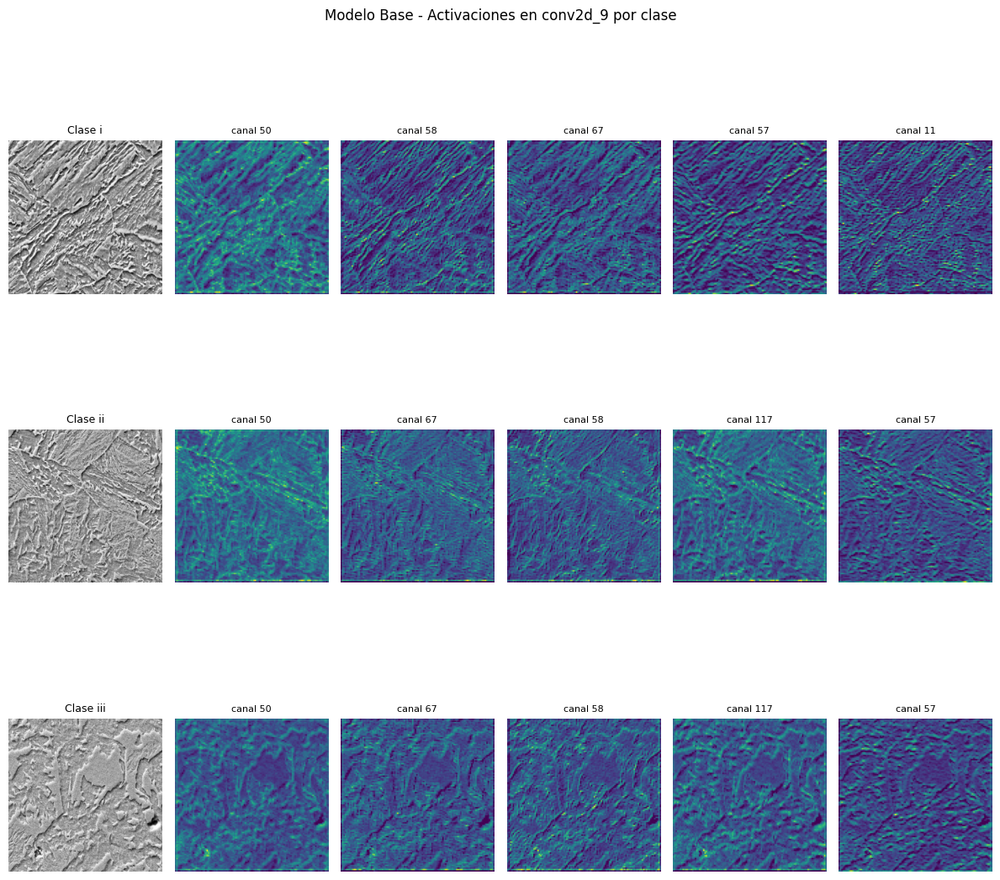

In [68]:
# --- 1) Identificar las capas convolucionales del modelo personalizado ---
capas_conv_base = [layer.name for layer in modelo.layers if isinstance(layer, tf.keras.layers.Conv2D)]
print("Capas convolucionales detectadas en el modelo base:", capas_conv_base)

# --- 2) Crear el modelo extractor de activaciones ---
modelo_activaciones_base = tf.keras.Model(
    inputs=modelo.input,
    outputs=[modelo.get_layer(n).output for n in capas_conv_base]
)

# --- 3) Función para preparar imagen para el modelo base (solo 1 canal) ---
def preparar_para_base_simple(ruta):
    img, _ = cargar_imagen(tf.constant(ruta), 0)   # (224, 224, 1)
    return img, tf.expand_dims(img, 0)            # imagen original y lote (1, 224, 224, 1)

# --- 4) Función para graficar activaciones ---
def mostrar_activaciones_base(img_gris, activaciones, nombres, n_canales=16, titulo=""):
    cols = n_canales // 2 + 1
    for nombre, act in zip(nombres, activaciones):
        act = act[0] # Quitar dimensión de lote
        # Seleccionar los canales con mayor activación promedio
        top = np.argsort(act.mean(axis=(0, 1)))[::-1][:n_canales]

        plt.figure(figsize=(14, 4))
        plt.subplot(2, cols, 1)
        plt.imshow(img_gris.numpy().squeeze(), cmap="gray")
        plt.title("Original", fontsize=8); plt.axis("off")
        for k, c in enumerate(top):
            plt.subplot(2, cols, k + 2 + (k >= n_canales // 2))
            plt.imshow(act[:, :, c], cmap="viridis")
            plt.title(f"canal {c}", fontsize=7); plt.axis("off")
        plt.suptitle(f"{titulo} | {nombre} {act.shape}", fontsize=10)
        plt.tight_layout(); plt.show()

# --- 5) Visualización de una imagen de test en todas las capas convolucionales ---
ruta_ejemplo = test_ds["ruta"].iloc[0]
clase_ejemplo = test_ds["clase"].iloc[0]
img_gris, lote = preparar_para_base_simple(ruta_ejemplo)
activaciones = modelo_activaciones_base.predict(lote, verbose=0)

print("\nGenerando mapas de características para una imagen de ejemplo:")
mostrar_activaciones_base(img_gris, activaciones, capas_conv_base,
                           titulo=f"Modelo Base - Clase real: {clase_ejemplo}")

# --- 6) Comparación: una imagen de cada clase en la segunda capa convolucional ---
if len(capas_conv_base) > 1:
    capa_comparar = capas_conv_base[1] # Usamos la segunda convolución como referencia para comparar texturas
    idx_capa = capas_conv_base.index(capa_comparar)

    plt.figure(figsize=(12, 4 * len(clases)))
    for f, cl in enumerate(clases):
        ruta = test_ds[test_ds["clase"] == cl]["ruta"].iloc[0]
        img_gris, lote = preparar_para_base_simple(ruta)
        act = modelo_activaciones_base.predict(lote, verbose=0)[idx_capa][0]
        top = np.argsort(act.mean(axis=(0, 1)))[::-1][:5]

        plt.subplot(len(clases), 6, f * 6 + 1)
        plt.imshow(img_gris.numpy().squeeze(), cmap="gray")
        plt.title(f"Clase {cl}", fontsize=9); plt.axis("off")
        for k, c in enumerate(top):
            plt.subplot(len(clases), 6, f * 6 + k + 2)
            plt.imshow(act[:, :, c], cmap="viridis")
            plt.title(f"canal {c}", fontsize=8); plt.axis("off")
    plt.suptitle(f"Modelo Base - Activaciones en {capa_comparar} por clase", fontsize=12)
    plt.tight_layout(); plt.show()

i                            198
ii                           102
iii                          86
Tamaño de la imagen: (512, 384), modo: P


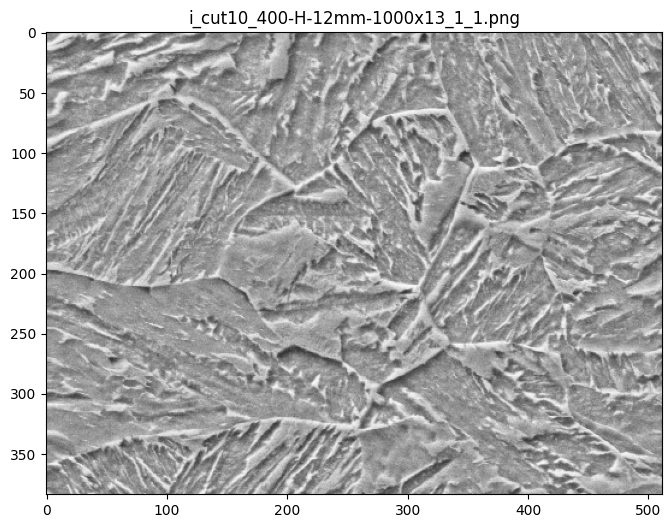

In [41]:
import os
from PIL import Image

ruta = '/content/drive/MyDrive/Proyecto IA2/Bainitic Microstructures/testset'

# 1 Cuántas imágenes hay por clase
for clase in sorted(os.listdir(ruta)):
  carpeta = os.path.join(ruta, clase)
  if os.path.isdir(carpeta) and not clase.startswith("."):
    print(f"{clase:28s} {len(os.listdir(carpeta))}")

# Tamaño y modo de una de las imagenes del dataset original
ejemplo_clase = "i"
ejemplo = os.listdir(os.path.join(ruta, ejemplo_clase))[0]
img = Image.open(os.path.join(ruta, ejemplo_clase, ejemplo))
print(f"Tamaño de la imagen: {img.size}, modo: {img.mode}")

# Grafias imagen original sin redimensión
plt.figure(figsize=(8, 6))
plt.imshow(img, cmap="gray")
plt.title(ejemplo)
plt.show()

In [42]:
ruta = '/content/drive/MyDrive/Proyecto IA2/Bainitic Microstructures/testset'
CLASES_EXCLUIDAS = [""]
# 1) Recorrer las carpetas y anotar (ruta, clase) de cada imagen
filas = []
for clase in sorted(os.listdir(ruta)):
    carpeta = os.path.join(ruta, clase)
    if not os.path.isdir(carpeta) or clase.startswith("."):
        continue                                  # ignora .ipynb_checkpoints
    if clase in CLASES_EXCLUIDAS:
        continue                                  # aquí se excluye la clase
    for archivo in os.listdir(carpeta):
        if archivo.lower().endswith(".png"):
            filas.append({"ruta": os.path.join(carpeta, archivo), "clase": clase})

df_test = pd.DataFrame(filas)

# 2) Pasar cada clase a un número (0, 1, 2, ...)
clases = sorted(df_test["clase"].unique())
clase_a_id = {c: i for i, c in enumerate(clases)}
df_test["label"] = df_test["clase"].map(clase_a_id)

print("Clases:", clases)
print("Total imágenes:", len(df_test))
print(df_test["clase"].value_counts())
df_test

Clases: ['i', 'ii', 'iii']
Total imágenes: 386
clase
i      198
ii     102
iii     86
Name: count, dtype: int64


,ruta,clase,label
0,/content/drive/MyDrive/Proyecto IA2/Bainitic M...,i,0
1,/content/drive/MyDrive/Proyecto IA2/Bainitic M...,i,0
2,/content/drive/MyDrive/Proyecto IA2/Bainitic M...,i,0
3,/content/drive/MyDrive/Proyecto IA2/Bainitic M...,i,0
4,/content/drive/MyDrive/Proyecto IA2/Bainitic M...,i,0
...,...,...,...
381,/content/drive/MyDrive/Proyecto IA2/Bainitic M...,iii,2
382,/content/drive/MyDrive/Proyecto IA2/Bainitic M...,iii,2
383,/content/drive/MyDrive/Proyecto IA2/Bainitic M...,iii,2
384,/content/drive/MyDrive/Proyecto IA2/Bainitic M...,iii,2


In [47]:
test_ds, temp_ds = train_test_split(
    df_test, test_size=0.1, stratify=df_test["label"], random_state=42
)

# Verificar que cada conjunto tenga todas las clases
resumen = pd.concat({
    "train": test_ds["clase"].value_counts(),
}, axis=1)
print(resumen)
print("\nTotales:", len(train_df), len(val_df))

       train
clase       
i        178
ii        92
iii       77

Totales: 652 280


## **Modelo del pipeline evaluado en el conjunto de test**

In [49]:
# Creamos el dataset de TensorFlow para el conjunto de prueba usando la función predefinida
test_dataset_tf = crear_dataset(test_ds, entrenamiento=False)

# Evaluamos el modelo de Transfer Learning con el dataset correcto
loss, accuracy = modelo.evaluate(test_dataset_tf)
print(f"\nLoss en test: {loss:.4f}")
print(f"Accuracy en test: {accuracy:.4f}")

11/11 ━━━━━━━━━━━━━━━━━━━━ 73s 7s/step - accuracy: 0.2651 - loss: 7.4947

Loss en test: 7.4947
Accuracy en test: 0.2651


# **EFFICIENTNETB0**

In [50]:
from tensorflow.keras.applications import EfficientNetB0

def crear_modelo_tl(n_clases):
    entradas = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1))
    x = data_augmentation(entradas)
    x = layers.Concatenate()([x, x, x])      # gris -> 3 canales (lo que espera la red)

    base = EfficientNetB0(include_top=False, weights="imagenet",
                          input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False                    # Fase 1: congelada

    x = base(x, training=False)               # su BN queda en modo inferencia
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    salidas = layers.Dense(n_clases, activation="softmax")(x)
    return tf.keras.Model(entradas, salidas, name="effnet_tl"), base

modelo_tl, base = crear_modelo_tl(len(clases))
modelo_tl.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])

callbacks = [
    #tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8,
                                     #restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                         patience=3, verbose=1),
]

historia_tl = modelo_tl.fit(train_ds, validation_data=val_ds, epochs=70,
                            class_weight=class_weight, callbacks=callbacks)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/70
21/21 ━━━━━━━━━━━━━━━━━━━━ 18s 268ms/step - accuracy: 0.4433 - loss: 1.0470 - val_accuracy: 0.6357 - val_loss: 0.8239 - learning_rate: 0.0010
Epoch 2/70
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 113ms/step - accuracy: 0.6242 - loss: 0.7953 - val_accuracy: 0.7250 - val_loss: 0.6835 - learning_rate: 0.0010
Epoch 3/70
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 118ms/step - accuracy: 0.7025 - loss: 0.7168 - val_accuracy: 0.7643 - val_loss: 0.6093 - learning_rate: 0.0010
Epoch 4/70
21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 123ms/step - accuracy: 0.7515 - loss: 0.6497 - val_accuracy: 0.7893 - val_loss: 0.5672 - learning_rate: 0.0010
Epoch 5/70
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 115ms/step - accuracy: 0.7561 - loss: 0.6217 - val_accuracy: 0.7929 - val_loss: 0.5289 - learning_rate: 0.0010
Epoch 6/70
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 115ms/step - accuracy: 0.7730 - loss: 0.5548 - val_accuracy: 0.8214 - val_loss: 0.5028 - learning_rate: 0.0010
Epoch 7/70
21/21 ━━━━━━━━━━━━━━━━━━━

In [51]:
base.summary()

Model: "efficientnetb0"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_3         │ (None, 224, 224,  │          0 │ input_layer_5[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          7 │ rescaling_3[0][0] │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_4         │ (None, 224, 224,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_4[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        512 │ block1a_se_excit

 Total params: 4,049,571 (15.45 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 4,049,571 (15.45 MB)

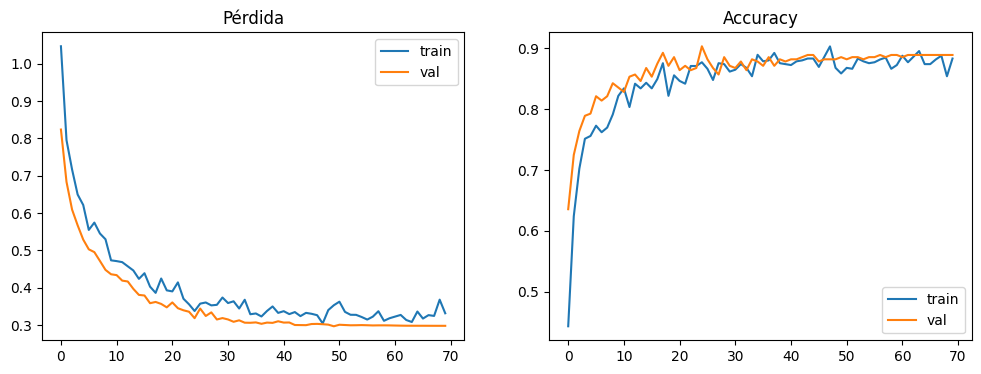

In [52]:
h = historia_tl.history
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="val")
ax[0].set_title("Pérdida"); ax[0].legend()
ax[1].plot(h["accuracy"], label="train"); ax[1].plot(h["val_accuracy"], label="val")
ax[1].set_title("Accuracy"); ax[1].legend()
plt.show()

## **Features y filtros de la EfficientNetB0**

stem_conv (3, 3, 3, 32)


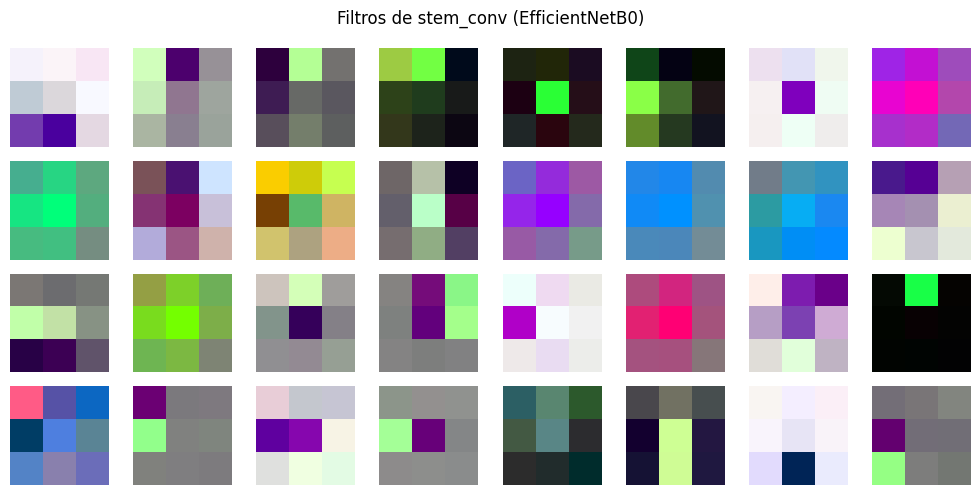

In [57]:
base = modelo_tl.get_layer("efficientnetb0")
capa = base.get_layer("stem_conv")
w = capa.get_weights()[0]
print(capa.name, w.shape)        # (3, 3, 3, 32)

n = w.shape[-1]
plt.figure(figsize=(10, 5))
for i in range(n):
    f = w[:, :, :, i]
    f = (f - f.min()) / (f.max() - f.min() + 1e-8)   # normalizar cada filtro
    plt.subplot(4, 8, i + 1)
    plt.imshow(f)
    plt.axis("off")
plt.suptitle("Filtros de stem_conv (EfficientNetB0)")
plt.tight_layout(); plt.show()

stem_activation    (1, 112, 112, 32)
block2b_add        (1, 56, 56, 24)
block3b_add        (1, 28, 28, 40)
block5c_add        (1, 14, 14, 112)
top_activation     (1, 7, 7, 1280)


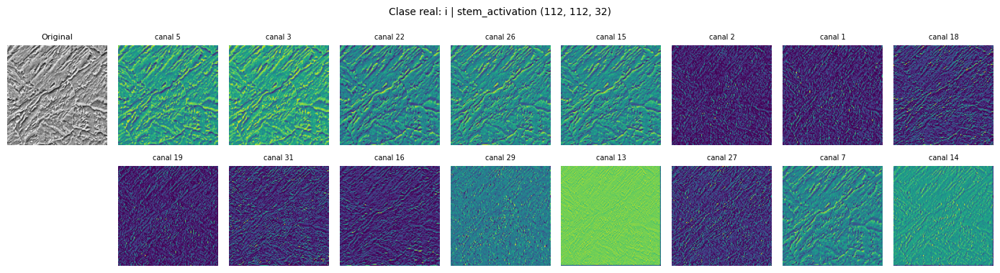

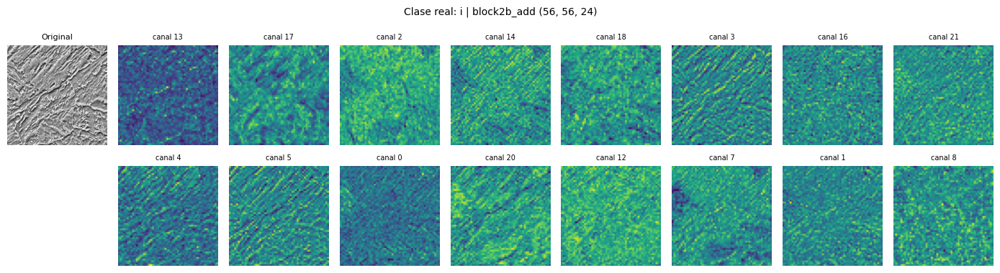

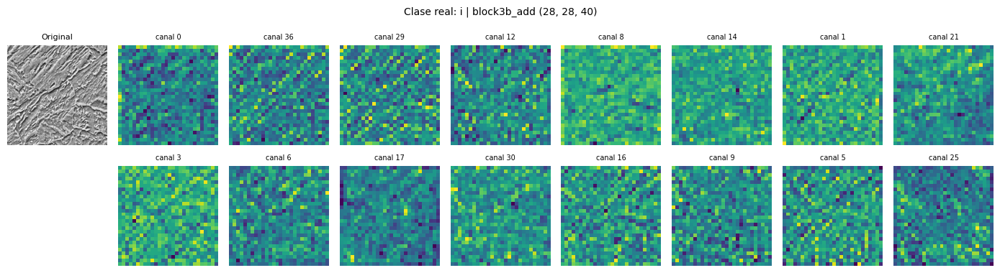

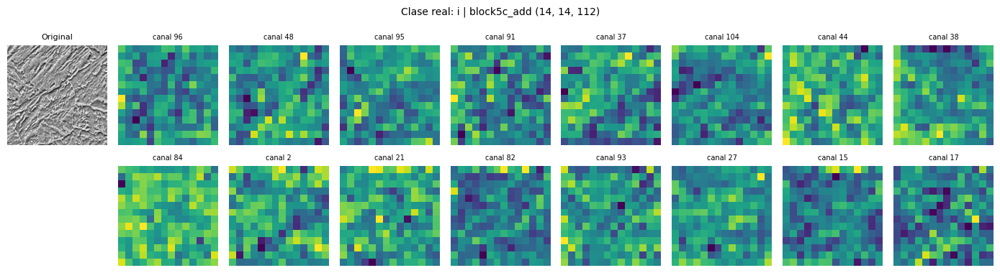

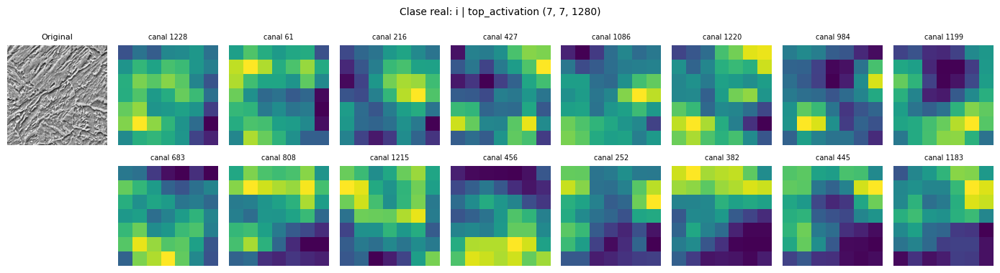

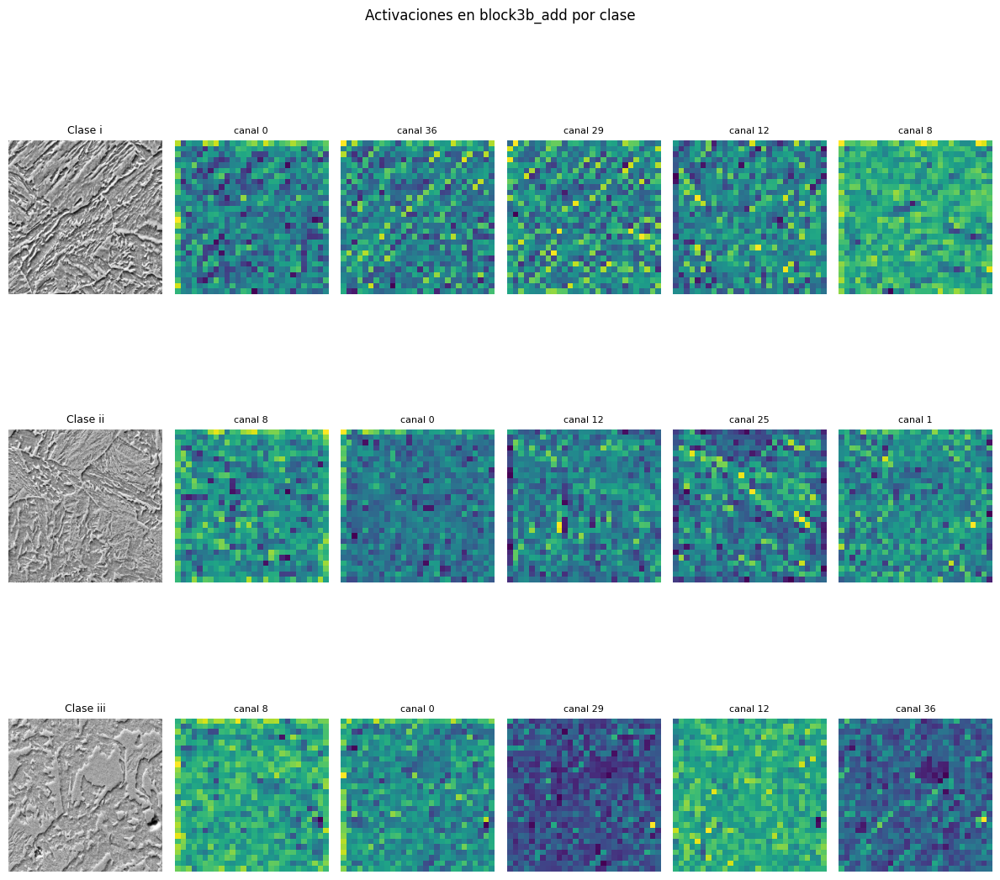

In [60]:
# ============================================================
# VISUALIZAR ACTIVACIONES INTERMEDIAS DE EFFICIENTNETB0
# ============================================================

# --- 1) Obtener la red base (sirve con el modelo entrenado o el cargado) ---
try:
    base
except NameError:
    base = model_tl_bainitic_test.get_layer("efficientnetb0")

# --- 2) Capas a visualizar (de superficial a profunda) ---
capas_interes = [
    "stem_activation",   # 112x112x32  -> bordes y contrastes
    "block2b_add",       # 56x56x24    -> texturas finas
    "block3b_add",       # 28x28x40    -> patrones locales
    "block5c_add",       # 14x14x112   -> estructuras más grandes
    "top_activation",    # 7x7x1280    -> lo que usa el clasificador
]
modelo_activaciones = tf.keras.Model(
    inputs=base.input,
    outputs=[base.get_layer(n).output for n in capas_interes],
)

# --- 3) Preparar imagen con el mismo preprocesamiento del entrenamiento ---
def preparar_para_base(ruta):
    img, _ = cargar_imagen(tf.constant(ruta), 0)   # (224, 224, 1), valores 0-255
    img3 = tf.concat([img, img, img], axis=-1)     # gris -> 3 canales
    return img, tf.expand_dims(img3, 0)            # imagen original y lote (1, 224, 224, 3)

# --- 4) Graficar los canales más activos de cada capa ---
def mostrar_activaciones(img_gris, activaciones, nombres, n_canales=16, titulo=""):
    cols = n_canales // 2 + 1
    for nombre, act in zip(nombres, activaciones):
        act = act[0]
        top = np.argsort(act.mean(axis=(0, 1)))[::-1][:n_canales]

        plt.figure(figsize=(14, 4))
        plt.subplot(2, cols, 1)
        plt.imshow(img_gris.numpy().squeeze(), cmap="gray")
        plt.title("Original", fontsize=8); plt.axis("off")
        for k, c in enumerate(top):
            plt.subplot(2, cols, k + 2 + (k >= n_canales // 2))
            plt.imshow(act[:, :, c], cmap="viridis")
            plt.title(f"canal {c}", fontsize=7); plt.axis("off")
        plt.suptitle(f"{titulo} | {nombre} {act.shape}", fontsize=10)
        plt.tight_layout(); plt.show()

# --- 5) Una imagen del test pasando por todas las capas ---
ruta_ejemplo = test_ds["ruta"].iloc[0]
clase_ejemplo = test_ds["clase"].iloc[0]
img_gris, lote = preparar_para_base(ruta_ejemplo)
activaciones = modelo_activaciones.predict(lote, verbose=0)

for n, a in zip(capas_interes, activaciones):
    print(f"{n:18s} {a.shape}")
mostrar_activaciones(img_gris, activaciones, capas_interes,
                     titulo=f"Clase real: {clase_ejemplo}")

# --- 6) Comparación: una imagen de cada clase en una misma capa ---
capa_comparar = "block3b_add"
idx_capa = capas_interes.index(capa_comparar)

plt.figure(figsize=(12, 4 * len(clases)))
for f, cl in enumerate(clases):
    ruta = test_ds[test_ds["clase"] == cl]["ruta"].iloc[0]
    img_gris, lote = preparar_para_base(ruta)
    act = modelo_activaciones.predict(lote, verbose=0)[idx_capa][0]
    top = np.argsort(act.mean(axis=(0, 1)))[::-1][:5]

    plt.subplot(len(clases), 6, f * 6 + 1)
    plt.imshow(img_gris.numpy().squeeze(), cmap="gray")
    plt.title(f"Clase {cl}", fontsize=9); plt.axis("off")
    for k, c in enumerate(top):
        plt.subplot(len(clases), 6, f * 6 + k + 2)
        plt.imshow(act[:, :, c], cmap="viridis")
        plt.title(f"canal {c}", fontsize=8); plt.axis("off")
plt.suptitle(f"Activaciones en {capa_comparar} por clase")
plt.tight_layout(); plt.show()

## **Evaluación del modelo en datos test**

In [61]:
# Creamos el dataset de TensorFlow para el conjunto de prueba usando la función predefinida
test_dataset_tf = crear_dataset(test_ds, entrenamiento=False)

# Evaluamos el modelo de Transfer Learning con el dataset correcto
loss, accuracy, precision, recall, f1-score = modelo_tl.evaluate(test_dataset_tf)
print(f"\nLoss en test: {loss:.4f}")
print(f"Accuracy en test: {accuracy:.4f}")

11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 158ms/step - accuracy: 0.7723 - loss: 0.5643

Loss en test: 0.5643
Accuracy en test: 0.7723


# **METRICAS**

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 63ms/step - accuracy: 0.2651 - loss: 7.4947
Métricas Keras: {'accuracy': 0.2651296854019165, 'loss': 7.49470329284668}
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 73ms/step
Accuracy:           0.2651
Precision macro:    0.0884
Recall macro:       0.3333
F1-score macro:    0.1397
Precision weighted: 0.0703
Recall weighted:    0.2651
F1-score weighted:  0.1111

Métricas por clase:
              precision    recall  f1-score   support

           i     0.0000    0.0000    0.0000       178
          ii     0.2651    1.0000    0.4191        92
         iii     0.0000    0.0000    0.0000        77

    accuracy                         0.2651       347
   macro avg     0.0884    0.3333    0.1397       347
weighted avg     0.0703    0.2651    0.1111       347



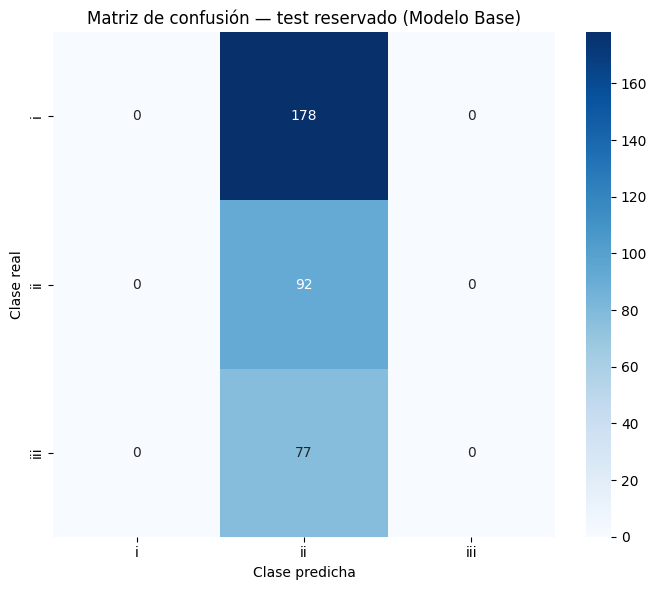

In [63]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix

# Evaluación únicamente sobre el testset optimizado en TF
resultados = modelo.evaluate(test_dataset_tf, verbose=1, return_dict=True)
print('Métricas Keras:', resultados)

# Extraemos las etiquetas reales del DataFrame de prueba
y_real = test_ds['label'].to_numpy()

# Realizamos las predicciones utilizando el dataset de TensorFlow
probabilidades = modelo.predict(test_dataset_tf, verbose=1)
y_pred = np.argmax(probabilidades, axis=1)

accuracy = accuracy_score(y_real, y_pred)
precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
    y_real, y_pred, labels=np.arange(len(clases)), average='macro', zero_division=0)
presicion_weighted, recall_weighted, f1_weighted, _ = precision_recall_fscore_support(
    y_real, y_pred, labels=np.arange(len(clases)), average='weighted', zero_division=0)

print(f'Accuracy:           {accuracy:.4f}')
print(f'Precision macro:    {precision_macro:.4f}')
print(f'Recall macro:       {recall_macro:.4f}')
print(f'F1-score macro:    {f1_macro:.4f}')
print(f'Precision weighted: {presicion_weighted:.4f}')
print(f'Recall weighted:    {recall_weighted:.4f}')
print(f'F1-score weighted:  {f1_weighted:.4f}')
print('\nMétricas por clase:')
print(classification_report(y_real, y_pred,
                            labels=np.arange(len(clases)), target_names=clases,
                            digits=4, zero_division=0))

matriz = confusion_matrix(y_real, y_pred, labels=np.arange(len(clases)))
plt.figure(figsize=(max(7, len(clases)), max(6, len(clases) * 0.8)))
sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues',
            xticklabels=clases, yticklabels=clases)
plt.xlabel('Clase predicha')
plt.ylabel('Clase real')
plt.title('Matriz de confusión — test reservado (Modelo Base)')
plt.tight_layout()
plt.show()

### Análisis Visual de Predicciones del Modelo Base
Con este bloque graficaremos imágenes de prueba con sus etiquetas reales versus la predicción realizada por el Modelo Base para comprobar el colapso de clase.

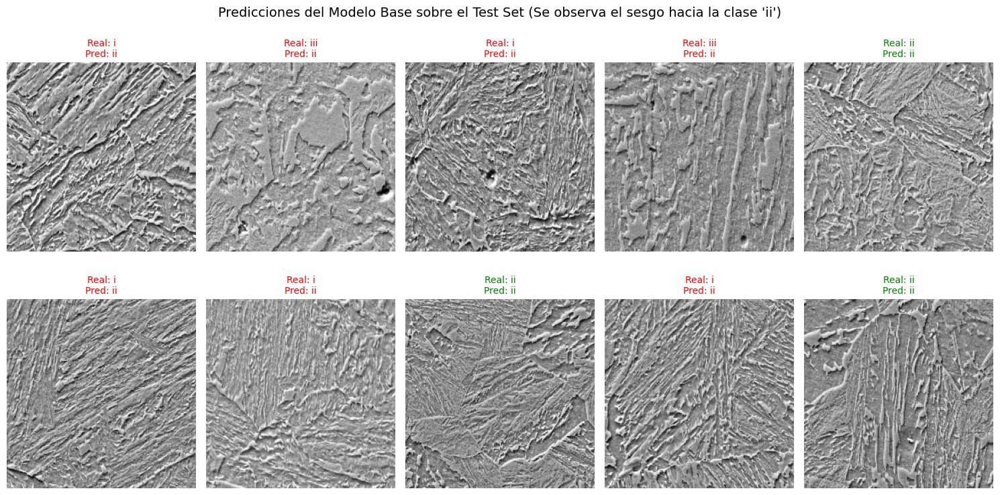

In [67]:
# Tomamos un lote del dataset de prueba y realizamos predicciones con el Modelo Base
for imgs_lote, labs_lote in test_dataset_tf.take(1):
    preds_lote = modelo.predict(imgs_lote, verbose=0)
    preds_clase = np.argmax(preds_lote, axis=1)

    plt.figure(figsize=(15, 8))
    for i in range(10):
        plt.subplot(2, 5, i + 1)
        plt.imshow(imgs_lote[i].numpy().squeeze(), cmap="gray")
        color = "green" if preds_clase[i] == labs_lote[i].numpy() else "red"
        plt.title(f"Real: {clases[labs_lote[i]]}\nPred: {clases[preds_clase[i]]}", color=color, fontsize=10)
        plt.axis("off")
    plt.suptitle("Predicciones del Modelo Base sobre el Test Set (Se observa el sesgo hacia la clase 'ii')", fontsize=14)
    plt.tight_layout()
    plt.show()

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 83ms/step - accuracy: 0.7723 - loss: 0.5643
Métricas Keras: {'accuracy': 0.7723342776298523, 'loss': 0.5642502903938293}
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 277ms/step
Accuracy:           0.7723
Precision macro:    0.8407
Recall macro:       0.7243
F1-score macro:    0.7025
Precision weighted: 0.8654
Recall weighted:    0.7723
F1-score weighted:  0.7617

Métricas por clase:
              precision    recall  f1-score   support

           i     0.9679    0.8483    0.9042       178
          ii     0.5542    1.0000    0.7132        92
         iii     1.0000    0.3247    0.4902        77

    accuracy                         0.7723       347
   macro avg     0.8407    0.7243    0.7025       347
weighted avg     0.8654    0.7723    0.7617       347



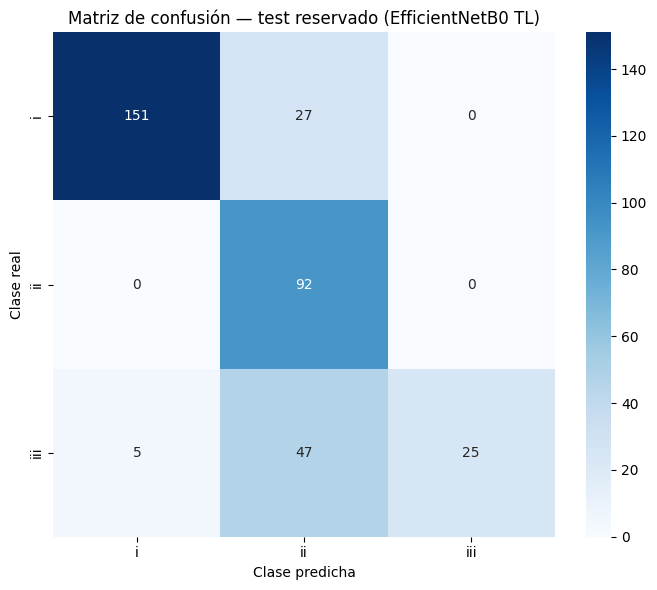

In [65]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix

# Evaluación únicamente sobre el testset optimizado en TF
resultados = modelo_tl.evaluate(test_dataset_tf, verbose=1, return_dict=True)
print('Métricas Keras:', resultados)

# Extraemos las etiquetas reales del DataFrame de prueba
y_real = test_ds['label'].to_numpy()

# Realizamos las predicciones utilizando el dataset de TensorFlow y el modelo correcto (modelo_tl)
probabilidades = modelo_tl.predict(test_dataset_tf, verbose=1)
y_pred = np.argmax(probabilidades, axis=1)

accuracy = accuracy_score(y_real, y_pred)
precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
    y_real, y_pred, labels=np.arange(len(clases)), average='macro', zero_division=0)
presicion_weighted, recall_weighted, f1_weighted, _ = precision_recall_fscore_support(
    y_real, y_pred, labels=np.arange(len(clases)), average='weighted', zero_division=0)

print(f'Accuracy:           {accuracy:.4f}')
print(f'Precision macro:    {precision_macro:.4f}')
print(f'Recall macro:       {recall_macro:.4f}')
print(f'F1-score macro:    {f1_macro:.4f}')
print(f'Precision weighted: {presicion_weighted:.4f}')
print(f'Recall weighted:    {recall_weighted:.4f}')
print(f'F1-score weighted:  {f1_weighted:.4f}')
print('\nMétricas por clase:')
print(classification_report(y_real, y_pred,
                            labels=np.arange(len(clases)), target_names=clases,
                            digits=4, zero_division=0))

matriz = confusion_matrix(y_real, y_pred, labels=np.arange(len(clases)))
plt.figure(figsize=(max(7, len(clases)), max(6, len(clases) * 0.8)))
sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues',
            xticklabels=clases, yticklabels=clases)
plt.xlabel('Clase predicha')
plt.ylabel('Clase real')
plt.title('Matriz de confusión — test reservado (EfficientNetB0 TL)')
plt.tight_layout()
plt.show()